# PowerPaint — Amazon product image inpainting

**COMP8410 Assignment 1 | Pair 1**

This notebook evaluates PowerPaint v2 on the same Amazon Berkeley Objects (ABO) images and masks as `BrushNet.ipynb`. The aim is to see how accurately it reconstructs missing product regions while preserving the rest of the image.

I use the pretrained PowerPaint BrushNet checkpoint and Realistic Vision SD1.5 backbone. The results will be compared with BrushNet using the same evaluation metrics and case IDs.

**Reference:** [PowerPaint official repository](https://github.com/open-mmlab/PowerPaint).

## 1. Setup

I use the `.venv-powerpaint` kernel because PowerPaint and BrushNet require different package versions. The test uses 20 inference steps and seed 42.

To install any missing evaluation packages, use this in PowerShell (without changing PyTorch, Diffusers or Transformers):

`\.venv-powerpaint\Scripts\python.exe -m pip install pandas matplotlib scikit-image lpips ipykernel`

In [8]:
from pathlib import Path
import sys
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import lpips
from PIL import Image
from skimage.metrics import structural_similarity

# Find the Pair_01 folder
here = Path.cwd().resolve()
PAIR = next((p for p in [here, here / "Models/Pair_01", here.parent / "Models/Pair_01"]
             if (p / "datasets/test_cases.csv").exists()), None)
if PAIR is None:
    raise FileNotFoundError("Run Jupyter from the project root or Models/Pair_01")

DATA = PAIR / "datasets"
OUT = PAIR / "results/PowerPaint"
OUT.mkdir(parents=True, exist_ok=True)

# Use the same evaluation settings as BrushNet
SEED = 42
STEPS = 20
LIMIT = None
PROMPT = "a realistic product photograph with clean studio lighting and detailed textures"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Pair:", PAIR)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Pair: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_01
CUDA: True
GPU: NVIDIA GeForce RTX 3070 Ti Laptop GPU


## 2. Dataset

Both models use the same prepared 512 × 512 ABO photographs and saved masks. White areas in a mask are regenerated and black areas are kept.

The original photograph is the reference for reconstruction metrics. These artificial masks make the results reproducible, although they do not represent every real product-editing task.

Test cases: 300


,image_id,source,image_path,mask_path,mask_type,mask_coverage
0,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_small.png,small,0.10
1,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_medium.png,medium,0.25
2,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_large.png,large,0.40
3,img_0002,25\2593d7a0.jpg,images/img_0002.png,masks/img_0002_small.png,small,0.10
4,img_0002,25\2593d7a0.jpg,images/img_0002.png,masks/img_0002_medium.png,medium,0.25


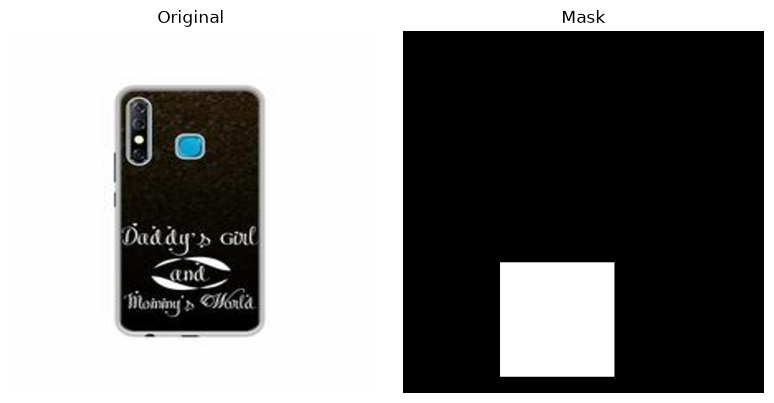

In [9]:
cases = pd.read_csv(DATA / "test_cases.csv")
needed = {"image_id", "image_path", "mask_path", "mask_type"}
assert needed.issubset(cases.columns), f"Missing columns: {needed - set(cases.columns)}"
print("Test cases:", len(cases))
display(cases.head())

def load_case(row):
    image = Image.open(DATA / row["image_path"]).convert("RGB").resize((512, 512))
    mask = Image.open(DATA / row["mask_path"]).convert("L").resize(
        (512, 512), Image.Resampling.NEAREST
    )
    mask = mask.point(lambda x: 255 if x >= 128 else 0)
    return image, mask

image, mask = load_case(cases.iloc[0])
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(image)
ax[0].set_title("Original")
ax[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Mask")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## 3. Load PowerPaint

I use the local PowerPaint v2 checkpoint and Realistic Vision SD1.5 model. CPU offloading helps it run on my 8 GB GPU.

The safety checker is disabled only for this offline evaluation. Generated images still need to be reviewed before any public use.

This code uses the PowerPaint pipeline directly, without Gradio.

In [10]:
from transformers import CLIPTextModel
from diffusers import UniPCMultistepScheduler
from safetensors.torch import load_model

# Import the local PowerPaint source
SOURCE = PAIR / "models/sources/PowerPaint"
CHECKPOINT = PAIR / "models/PowerPaint"
BASE = CHECKPOINT / "realisticVisionV60B1_v51VAE"
sys.path.insert(0, str(SOURCE))

from powerpaint.models.BrushNet_CA import BrushNetModel
from powerpaint.models.unet_2d_condition import UNet2DConditionModel
from powerpaint.pipelines.pipeline_PowerPaint_Brushnet_CA import StableDiffusionPowerPaintBrushNetPipeline
from powerpaint.utils.utils import TokenizerWrapper, add_tokens

assert BASE.is_dir(), "PowerPaint base model not found"
assert (CHECKPOINT / "PowerPaint_Brushnet").is_dir(), "PowerPaint checkpoint not found"

dtype = torch.float16 if torch.cuda.is_available() else torch.float32

# Load the two model branches
unet = UNet2DConditionModel.from_pretrained(
    "runwayml/stable-diffusion-v1-5", subfolder="unet", torch_dtype=dtype
)
text_encoder_brushnet = CLIPTextModel.from_pretrained(
    "runwayml/stable-diffusion-v1-5", subfolder="text_encoder", torch_dtype=dtype
)
brushnet = BrushNetModel.from_unet(unet)

pipe = StableDiffusionPowerPaintBrushNetPipeline.from_pretrained(
    str(BASE), brushnet=brushnet, text_encoder_brushnet=text_encoder_brushnet,
    torch_dtype=dtype, low_cpu_mem_usage=False, safety_checker=None
)
pipe.unet = UNet2DConditionModel.from_pretrained(
    str(BASE), subfolder="unet", torch_dtype=dtype
)
pipe.tokenizer = TokenizerWrapper(from_pretrained=str(BASE), subfolder="tokenizer")

# Add the task tokens used by PowerPaint
add_tokens(
    tokenizer=pipe.tokenizer,
    text_encoder=pipe.text_encoder_brushnet,
    placeholder_tokens=["P_ctxt", "P_shape", "P_obj"],
    initialize_tokens=["a", "a", "a"],
    num_vectors_per_token=10,
)

load_model(
    pipe.brushnet,
    str(CHECKPOINT / "PowerPaint_Brushnet/diffusion_pytorch_model.safetensors")
)
pipe.text_encoder_brushnet.load_state_dict(
    torch.load(CHECKPOINT / "PowerPaint_Brushnet/pytorch_model.bin", map_location="cpu"),
    strict=False,
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

if torch.cuda.is_available():
    pipe.enable_model_cpu_offload()

print("PowerPaint loaded")

c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\huggingface_hub\file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\diffusers\models\modeling_utils.py:110: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `Tru

11/03 01:36:53 - mmengine - INFO - Successfully add external embeddings: P_ctxt, P_shape, P_obj.
11/03 01:36:53 - mmengine - INFO - Successfully add trainable external embeddings: P_ctxt, P_shape, P_obj


C:\Users\royay\AppData\Local\Temp\ipykernel_28144\2738751280.py:53: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(CHECKPOINT / "PowerPaint_Brushnet/pytorch_model.

PowerPaint loaded


## 4. Evaluation metrics

I calculate the same metrics as in `BrushNet.ipynb` so the final comparison is consistent.

- **Masked PSNR and SSIM:** similarity to the original image inside the missing area (higher is better).
- **Masked LPIPS:** perceptual difference for the masked region's bounding-box crop (lower is better).
- **Unmasked SSIM:** how well the output preserves the area outside the mask (higher is better).
- **Time:** inference time in seconds, excluding model loading and metric calculations.

Metrics use the raw model output. I also save a composited result for display. The LPIPS score is an approximate region-based measure rather than pixel-level LPIPS.

In [11]:
# Keep LPIPS on CPU to save GPU memory
lpips_model = lpips.LPIPS(net="alex").eval().cpu()

def scores(original, generated, mask):
    gt = np.asarray(original, dtype=np.float32) / 255
    pred = np.asarray(generated, dtype=np.float32) / 255
    m = np.asarray(mask, dtype=np.uint8) > 0

    if not m.any() or m.all():
        raise ValueError("Mask must contain black and white pixels")

    # Reconstruction error in the masked region
    mse = np.mean((gt[m] - pred[m]) ** 2)
    psnr = float(-10 * np.log10(max(mse, 1e-12)))

    _, ssim_map = structural_similarity(
        gt, pred, channel_axis=2, data_range=1.0, full=True
    )
    if ssim_map.ndim == 3:
        ssim_map = ssim_map.mean(axis=2)

    # LPIPS on a crop around the mask
    yy, xx = np.where(m)
    y1, y2 = yy.min(), yy.max() + 1
    x1, x2 = xx.min(), xx.max() + 1
    cm = m[y1:y2, x1:x2, None]
    gt_crop = np.where(cm, gt[y1:y2, x1:x2], 0.5)
    pred_crop = np.where(cm, pred[y1:y2, x1:x2], 0.5)

    def tensor(a):
        return torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1).unsqueeze(0) * 2 - 1

    with torch.no_grad():
        distance = float(lpips_model(tensor(gt_crop), tensor(pred_crop)).item())

    return {
        "masked_psnr": psnr,
        "masked_ssim": float(ssim_map[m].mean()),
        "masked_lpips": distance,
        "unmasked_ssim": float(ssim_map[~m].mean()),
        "mask_coverage": float(m.mean()),
    }

def generate(image, mask, seed):
    # Hide the pixels selected for inpainting
    arr = np.asarray(image).copy()
    arr[np.asarray(mask) > 0] = 0
    masked_image = Image.fromarray(arr)

    generator = torch.Generator(
        "cuda" if torch.cuda.is_available() else "cpu"
    ).manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        raw = pipe(
            promptA="P_obj",
            promptB="P_obj",
            promptU=PROMPT,
            tradoff=1.0,
            tradoff_nag=1.0,
            image=masked_image,
            mask=mask.convert("RGB"),
            num_inference_steps=STEPS,
            generator=generator,
            brushnet_conditioning_scale=1.0,
            negative_promptA="P_obj",
            negative_promptB="P_obj",
            negative_promptU="",
            guidance_scale=7.5,
            width=512,
            height=512,
        ).images[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    # Keep the original pixels outside the edited area
    pasted = Image.composite(raw, image, mask)
    return raw, pasted, seconds

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\lpips\weights\v0.1\alex.pth


c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\lpips\lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.

## 5. Run evaluation

If a case fails, I record the error rather than leaving it out without explanation.

In [12]:
test_cases = cases.head(LIMIT) if LIMIT is not None else cases
records = []

for i, (_, row) in enumerate(test_cases.iterrows(), 1):
    case_id = f"{row['image_id']}_{row['mask_type']}"
    try:
        original, mask = load_case(row)
        raw, pasted, seconds = generate(original, mask, SEED)
        metrics = scores(original, raw, mask)

        raw.save(OUT / f"{case_id}_raw.png")
        pasted.save(OUT / f"{case_id}.png")

        records.append({
            "model": "PowerPaint", "case_id": case_id,
            "image_id": row["image_id"], "mask_type": row["mask_type"],
            "seed": SEED, "steps": STEPS, "prompt": PROMPT,
            "time_seconds": seconds, "status": "ok", "error": "", **metrics
        })
        print(f"{i}/{len(test_cases)}  {case_id}  {seconds:.1f}s  OK")
    except Exception as e:
        records.append({
            "model": "PowerPaint", "case_id": case_id,
            "image_id": row["image_id"], "mask_type": row["mask_type"],
            "seed": SEED, "steps": STEPS, "prompt": PROMPT,
            "status": "failed", "error": str(e)
        })
        print(f"{i}/{len(test_cases)}  {case_id}  FAILED: {e}")

    # Save after each case so a stopped run does not lose all results
    pd.DataFrame(records).to_csv(OUT / "metrics.csv", index=False)

results = pd.DataFrame(records)
print("Completed:", (results["status"] == "ok").sum(), "/", len(results))
display(results.head())

  0%|          | 0/20 [00:00<?, ?it/s]c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\diffusers\models\resnet.py:328: FutureWarning: `scale` is deprecated and will be removed in version 1.0.0. The `scale` argument is deprecated and will be ignored. Please remove it, as passing it will raise an error in the future. `scale` should directly be passed while calling the underlying pipeline component i.e., via `cross_attention_kwargs`.
  deprecate("scale", "1.0.0", deprecation_message)
c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-powerpaint\Lib\site-packages\diffusers\models\downsampling.py:136: FutureWarning: `scale` is deprecated and will be removed in version 1.0.0. The `scale` argument is deprecated and will be ignored. Please remove it, as passing it will raise an error in the future. `scale` should directly be passed while calling the underlying pipeline component i.e., via `cross_attentio

1/300  img_0001_small  7.1s  OK


100%|██████████| 20/20 [00:04<00:00,  4.53it/s]


2/300  img_0001_medium  5.8s  OK


100%|██████████| 20/20 [00:04<00:00,  4.61it/s]


3/300  img_0001_large  5.7s  OK


... (591 outputs left out)

299/300  img_0100_medium  6.0s  OK


100%|██████████| 20/20 [00:04<00:00,  4.10it/s]


300/300  img_0100_large  6.0s  OK
Completed: 300 / 300


,model,case_id,image_id,mask_type,seed,steps,prompt,time_seconds,status,error,masked_psnr,masked_ssim,masked_lpips,unmasked_ssim,mask_coverage
0,PowerPaint,img_0001_small,img_0001,small,42,20,a realistic product photograph with clean stud...,7.082481,ok,,5.899815,0.142360,0.627204,0.948778,0.100113
1,PowerPaint,img_0001_medium,img_0001,medium,42,20,a realistic product photograph with clean stud...,5.802848,ok,,8.177897,0.129048,0.598784,0.969831,0.250000
2,PowerPaint,img_0001_large,img_0001,large,42,20,a realistic product photograph with clean stud...,5.664052,ok,,4.810412,0.177316,0.778113,0.966513,0.400452
3,PowerPaint,img_0002_small,img_0002,small,42,20,a realistic product photograph with clean stud...,5.464192,ok,,5.103897,0.178804,0.786528,0.887561,0.100113
4,PowerPaint,img_0002_medium,img_0002,medium,42,20,a realistic product photograph with clean stud...,5.426160,ok,,5.421758,0.101569,0.779268,0.913815,0.250000


## 6. Results and examples

I report average results by mask size and show one original image alongside its mask and generated output. The full results are saved to CSV for `Comparison.ipynb`.

The averages only use successful runs, so I also report how many cases failed.

Failures: 0


masked_psnr        masked_ssim        masked_lpips         \
                 mean    std        mean    std         mean    std   
mask_type                                                             
large           8.409  2.422       0.232  0.078        0.756  0.092   
medium          8.503  2.821       0.224  0.104        0.737  0.109   
small           8.527  3.504       0.234  0.099        0.697  0.097   

          unmasked_ssim        time_seconds         
                   mean    std         mean    std  
mask_type                                           
large             0.932  0.054        5.977  0.126  
medium            0.925  0.056        5.986  0.120  
small             0.919  0.056        5.995  0.168

,mean
masked_psnr,8.480
masked_ssim,0.230
masked_lpips,0.730
unmasked_ssim,0.925
time_seconds,5.986


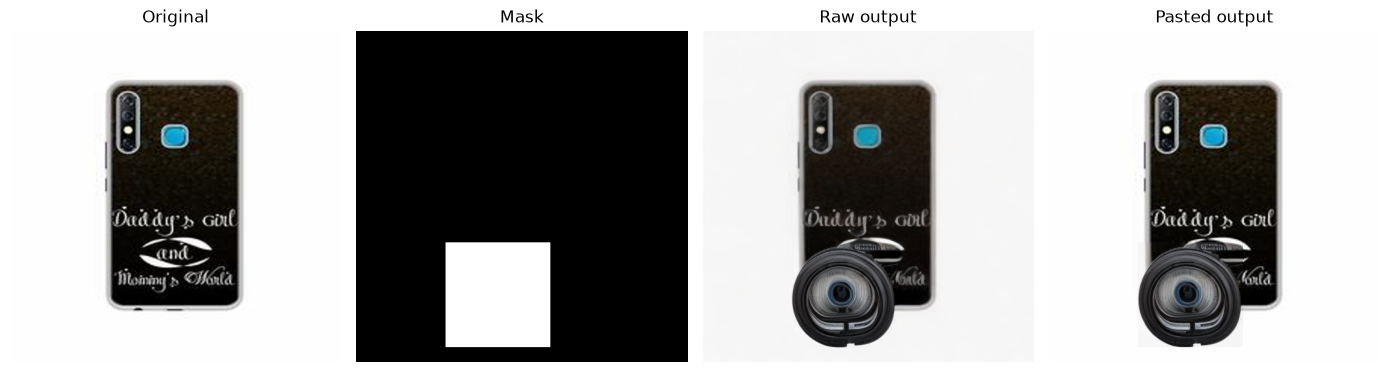

In [13]:
good = results[results["status"] == "ok"].copy()
print("Failures:", (results["status"] != "ok").sum())

if not good.empty:
    columns = [
        "masked_psnr", "masked_ssim", "masked_lpips",
        "unmasked_ssim", "time_seconds"
    ]
    display(good.groupby("mask_type")[columns].agg(["mean", "std"]).round(3))
    display(good[columns].mean().round(3).to_frame("mean"))

    sample = good.iloc[0]
    row = cases[
        (cases["image_id"] == sample["image_id"]) &
        (cases["mask_type"] == sample["mask_type"])
    ].iloc[0]

    original, mask = load_case(row)
    raw = Image.open(OUT / f"{sample['case_id']}_raw.png")
    pasted = Image.open(OUT / f"{sample['case_id']}.png")

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for ax, img, title in zip(
        axes, [original, mask, raw, pasted],
        ["Original", "Mask", "Raw output", "Pasted output"]
    ):
        ax.imshow(img, cmap="gray" if title == "Mask" else None)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "example_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

## 7. Notes for comparison and reflection

The results show that PowerPaint struggles to accurately reconstruct missing areas in product images. The average masked SSIM was 0.230, PSNR was 8.480, and LPIPS was 0.730. The reconstruction quality was relatively low across all three mask sizes, with an average inference time of approximately 6 seconds per image.

From the visual examples, PowerPaint sometimes generates unrelated objects instead of reconstructing the original product. For example, it generated circular metallic objects on phone cases, bags and furniture. This suggests that the model sometimes treats the masked regions as areas for inserting new objects rather than restoring the original content.

Some outputs preserve the overall appearance of the product, such as the furniture and washing machine examples. However, there are still visible changes to textures, shapes and details. PowerPaint also struggles with text reconstruction, as shown by the distorted labels on supplement bottles.

The average unmasked SSIM was 0.925, indicating that most areas outside the masks were preserved. However, the incorrect product details and unrelated objects would be problematic for Amazon product listings because the images may no longer accurately represent the products being sold.

Overall, PowerPaint can generate visually realistic content, but its reconstruction accuracy is inconsistent in this evaluation. These results also show the limitations of using a general text prompt and synthetic rectangular masks to evaluate product image restoration.

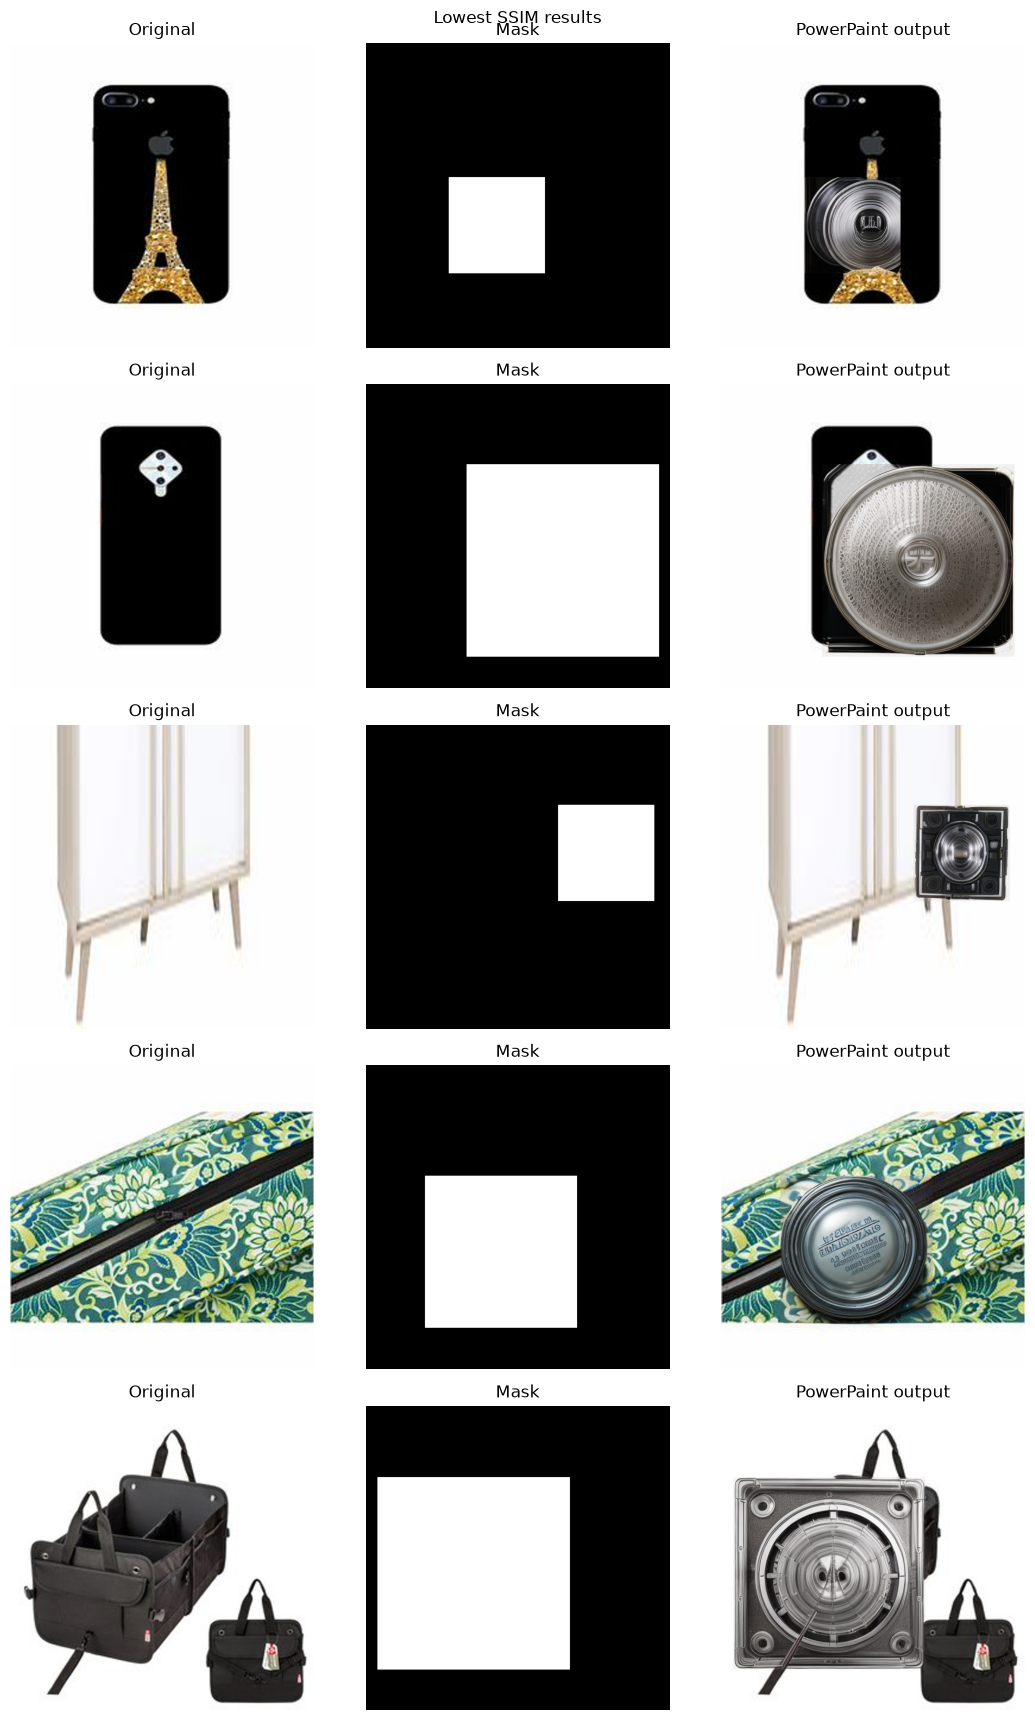

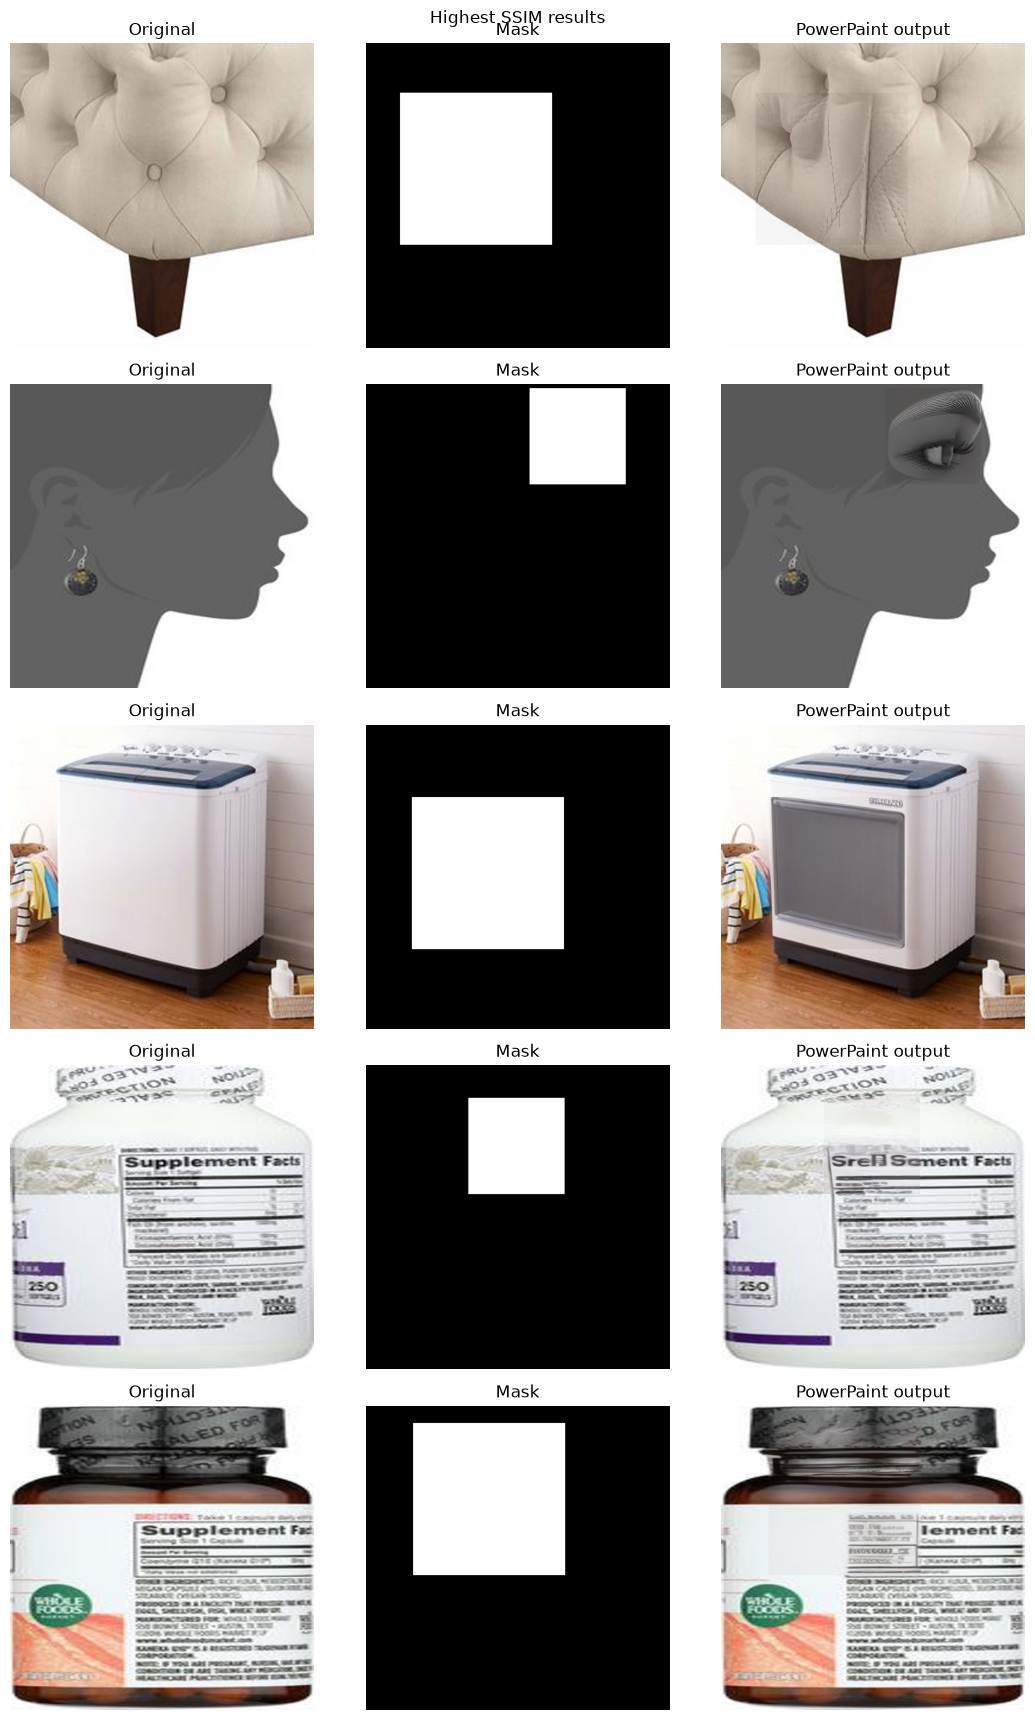

In [14]:
# Show the five lowest and highest SSIM cases
def show_examples(table, title):
    if table.empty:
        return

    fig, axes = plt.subplots(len(table), 3, figsize=(11, 3.5 * len(table)), squeeze=False)
    for i, (_, result) in enumerate(table.iterrows()):
        row = cases[
            (cases["image_id"] == result["image_id"]) &
            (cases["mask_type"] == result["mask_type"])
        ].iloc[0]
        original, mask = load_case(row)
        output = Image.open(OUT / f"{result['case_id']}.png")

        for ax, img, label in zip(
            axes[i], [original, mask, output],
            ["Original", "Mask", "PowerPaint output"]
        ):
            ax.imshow(img, cmap="gray" if label == "Mask" else None)
            ax.set_title(label)
            ax.axis("off")
        axes[i, 0].set_ylabel(f"SSIM: {result['masked_ssim']:.3f}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(good.nsmallest(5, "masked_ssim"), "Lowest SSIM results")
show_examples(good.nlargest(5, "masked_ssim"), "Highest SSIM results")